In [1]:
import xarray as xr
import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon
from operator import sub

In [3]:
def compute_reliability_score(y_true, y_pred, num_bins=10):
    """
    Compute the reliability score for probabilistic forecasts.

    Parameters:
    y_true (numpy array): Array of true binary outcomes (0 or 1).
    y_pred (numpy array): Array of predicted probabilities (between 0 and 1).
    num_bins (int): Number of bins to use for grouping predicted probabilities.

    Returns:
    float: The reliability score.
    """
    
    # Ensure y_true and y_pred are numpy arrays
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    
    # Initialize arrays to hold the average predicted probabilities and observed frequencies for each bin
    bin_avg_pred = np.zeros(num_bins)
    bin_avg_true = np.zeros(num_bins)
    bin_counts = np.zeros(num_bins)
    
    # Bin edges
    bin_edges = np.linspace(0, 1, num_bins + 1)
    
    # Assign each prediction to a bin
    bin_indices = np.digitize(y_pred, bin_edges, right=True) - 1
    bin_indices = np.clip(bin_indices, 0, num_bins - 1)  # Ensure indices are within valid range
    
    # Calculate bin statistics
    for i in range(num_bins):
        # Indices of predictions in the current bin
        bin_mask = (bin_indices == i)
        bin_count = np.sum(bin_mask)
        
        if bin_count > 0:
            # Average predicted probability for the current bin
            bin_avg_pred[i] = np.mean(y_pred[bin_mask])
            # Observed frequency (empirical probability) for the current bin
            bin_avg_true[i] = np.mean(y_true[bin_mask])
            bin_counts[i] = bin_count
    
    # Calculate the reliability score
    reliability_score = np.nansum((bin_avg_pred - bin_avg_true)**2 * bin_counts) / np.sum(bin_counts)
    
    return reliability_score

In [4]:
def compute_brier_skill_score(y_pred, t):
    """
    Compute the Brier Skill Score (BSS) for probabilistic forecasts.

    Parameters:
    y_pred (numpy array): Predicted probabilities.
    t (numpy array): True binary outcomes (0 or 1).

    Returns:
    float: The Brier Skill Score (BSS).
    """
    # Adjust y_pred to avoid edge cases
    y_pred = y_pred * 0.9999999999999
    
    # Mask to remove NaNs
    msk = np.where(~np.isnan(y_pred + t))
    y_pred = y_pred[msk]
    t = t[msk]
    
    # Calculate the base rate (climatological mean)
    base_rate = np.nanmean(t)
    
    # Calculate the Brier Score (BS)
    bs = np.nanmean((y_pred - t)**2)
    
    # Calculate the Brier Score for the reference forecast (BR)
    br = np.nanmean((base_rate - t)**2)
    
    # Calculate the Brier Skill Score (BSS)
    bss = 1 - (bs / br)
    
    return bss

In [5]:
def compute_resolution_score(predictions, observations, num_bins=10):
    """
    Compute the resolution score for probabilistic forecasts.

    Parameters:
    predictions (numpy array): Predicted probabilities.
    observations (numpy array): True binary outcomes (0 or 1).
    num_bins (int): Number of bins to use for grouping predicted probabilities.

    Returns:
    float: The resolution score.
    """
    # Adjust predictions to avoid edge cases
    predictions = predictions * 0.9999999999999
    
    # Mask to remove NaNs
    mask = np.where(~np.isnan(predictions + observations))
    predictions = predictions[mask]
    observations = observations[mask]
    
    # Calculate the base rate (climatological mean)
    base_rate = np.nanmean(observations)
    
    # Initialize arrays to hold the average observed frequencies and counts for each bin
    bin_obs_freq = np.zeros(num_bins)
    bin_counts = np.zeros(num_bins)
    
    # Bin edges
    bin_edges = np.linspace(0, 1, num_bins + 1)
    
    # Assign each prediction to a bin
    bin_indices = np.digitize(predictions, bin_edges, right=True) - 1
    bin_indices = np.clip(bin_indices, 0, num_bins - 1)  # Ensure indices are within valid range
    
    # Calculate bin statistics
    for i in range(num_bins):
        bin_mask = (bin_indices == i)
        bin_counts[i] = bin_mask.sum()
        
        if bin_counts[i] > 0:
            bin_obs_freq[i] = observations[bin_mask].mean()
    
    # Calculate the resolution score
    resolution = np.nansum(bin_counts * (bin_obs_freq - base_rate)**2) / np.sum(bin_counts)
    
    return resolution

In [6]:
def reliability_diagram(ypred, t, title=None, perfect_reliability_line=True, plot_hist=True, fig=None, ax=None, bin_minimum_pct=0.01, tercile_skill_area=True, scores=True):
    """
    Compute and plot a reliability diagram (calibration curve) with a normalized histogram of the forecast probabilities.

    Parameters:
    ypred (numpy array): Predicted probabilities.
    t (numpy array): True binary outcomes (0 or 1).
    title (str): Title for the plot.
    perfect_reliability_line (bool): Whether to plot the perfect reliability line.
    plot_hist (bool): Whether to plot the histogram of forecast probabilities.
    fig (matplotlib Figure): Figure object to plot on.
    ax (matplotlib Axes): Axes object to plot on.
    bin_minimum_pct (float): Minimum percentage of samples in a bin to include it in the plot.
    """

    ypred = ypred * 0.9999999999999  # Avoids edge cases with digitize
    assert ypred.shape == t.shape, 'Inconsistent shapes between ypred and t - {} vs {}'.format(ypred.shape, t.shape)
    
    # Mask to remove NaNs
    msk = np.where(~np.isnan(ypred + t))
    ypred = ypred[msk]
    t = t[msk]
    
    # Total number of non-NaN samples
    countnonnan = np.ones_like(ypred).sum()
    
    # Initialize arrays
    bin_avg_pred = np.zeros(10)
    bin_obs_freq = np.zeros(10)
    bin_counts = np.zeros(10)
    
    # Iterate over bins
    for i in range(10):
        bin_mask = (ypred >= i / 10.0) & (ypred < (i / 10.0 + 0.1))
        bin_counts[i] = bin_mask.sum()
        
        if bin_counts[i] > 0:
            bin_avg_pred[i] = ypred[bin_mask].mean()
            bin_obs_freq[i] = t[bin_mask].mean()
    
    # Compute bin centers
    bin_centers = (np.arange(10) + 0.5) / 10.0
    
    # Mask bins with insufficient data
    valid_bins = bin_counts / countnonnan >= bin_minimum_pct
    bin_centers = bin_centers[valid_bins]
    bin_avg_pred = bin_avg_pred[valid_bins]
    bin_obs_freq = bin_obs_freq[valid_bins]
    bin_counts = bin_counts[valid_bins]
    
    # Normalize bin counts for the histogram
    bin_counts = bin_counts / countnonnan
    
    if ax is None:
        fig, ax = plt.subplots()
    
    b1, t1 = ax.set_ylim(0, 1)
    l, r = ax.set_xlim(0, 1)

    #plt.hist(epoelm_xval[:, 0], bins=11)
    if tercile_skill_area:
        ur = Polygon([[0.33, 0.33 ], [0.33, 1], [1,1], [1, 1.33/2.0]], facecolor='gray', alpha=0.25)
        bl = Polygon([[0.33, 0.33 ], [0.33, 0], [0,0], [0, 0.33/2.0]], facecolor='gray', alpha=0.25)
        ax.add_patch(ur)
        ax.add_patch(bl)

        ax.text(0.66, 0.28, 'No Resolution')
        noresolution = ax.plot([0, 1], [0.33,0.33], lw=0.5, linestyle='dotted')

        noskill = ax.plot([0, 1], [0.33/2.0,1.33/2.0], lw=0.5, linestyle='dotted')
        figW, figH = ax.get_figure().get_size_inches()
        _, _, w, h = ax.get_position().bounds
        disp_ratio = (figH * h) / (figW * w)
        data_ratio = sub(*ax.get_ylim()) / sub(*ax.get_xlim())
        angle = (180.0/np.pi)*np.arctan(disp_ratio / data_ratio)
        ax.text(0.66, 0.45, 'No Skill', rotation=angle*0.5)

        ax.plot([0.33, 0.33], [0,1], lw=0.5, linestyle='dotted')
    
    # Plot the reliability diagram
    ax.plot(bin_centers, bin_obs_freq, marker='o', linestyle='-', color='red', label='Observed Frequency')
    
    # Plot the perfect reliability line
    if perfect_reliability_line:
        ax.plot([0, 1], [0, 1], linestyle='--', color='blue', label='Perfect Reliability')
    
    # Plot normalized histogram
    if plot_hist:
        ax.bar(bin_centers, bin_counts, width=0.1, color='violet', alpha=0.5, label='Normalized Counts')
    
    if scores:
        bss = compute_brier_skill_score(ypred, t)
        rel = compute_reliability_score(t, ypred)
        res = compute_resolution_score(ypred, t)
        ax.text( 0.7, 0.11, 'BSS: {:0.04f}'.format(bss))
        ax.text( 0.7, 0.06, 'REL: {:0.04f}'.format(rel))
        ax.text( 0.7, 0.01, 'RES: {:0.04f}'.format(res))
    
    ax.set_xlabel('Forecast Probability')
    ax.set_ylabel('Observed Frequency')
    ax.set_ylim([0, 1])
    ax.set_xlim([0, 1])
    if title is not None:
        ax.set_title(title)
    ax.legend(loc='upper left')
    
    plt.show()

## Week 1

In [7]:
y_pred = np.load('nonz_terciles_f_1.npy')
t = np.load('nonz_ohe_f_1.npy')

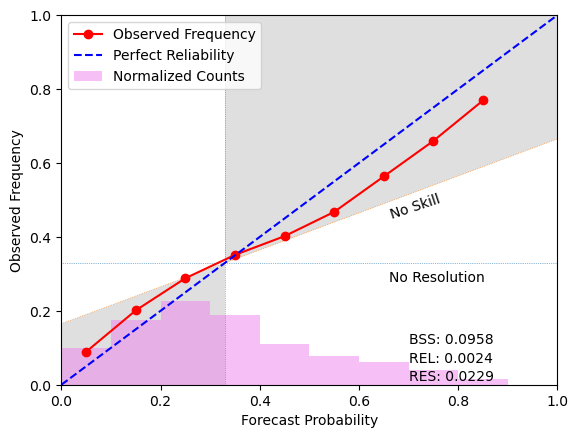

In [8]:
reliability_diagram(y_pred, t)

## Week 2 

In [9]:
y_pred = np.load('nonz_terciles_f_2.npy')
t = np.load('nonz_ohe_f_2.npy')

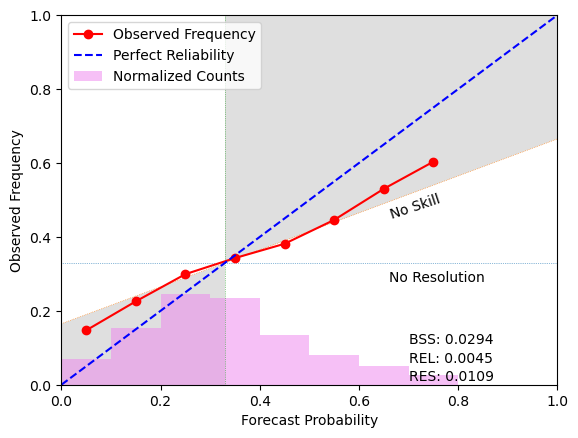

In [10]:
reliability_diagram(y_pred, t)

## Week 3&4

In [11]:
y_pred = np.load('nonz_terciles_f_34.npy')
t = np.load('nonz_ohe_f_34.npy')

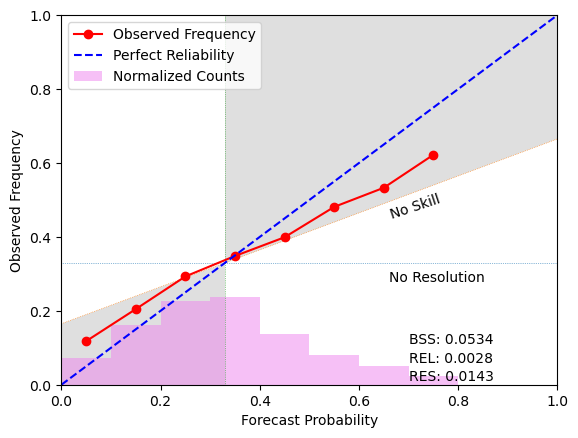

In [12]:
reliability_diagram(y_pred, t)

In [13]:
week1_elr_terciles = np.load('tercile_preds_elr_imd_week1.npy')
week2_elr_terciles = np.load('tercile_preds_elr_imd_week2.npy')
week34_elr_terciles = np.load('tercile_preds_elr_imd_week34.npy')

In [14]:
def make_ohe(array):
    p_33 = np.quantile(array, q=1/3)
    p_67 = np.quantile(array, q=2/3)
    
    ohe = np.zeros((array.shape[0],3))
    for i in range(len(array)):
        if array[i]<=p_33:
            ohe[i][0] = 1
        elif p_33<array[i]<=p_67:
            ohe[i][1] = 1
        elif array[i]>p_67:
            ohe[i][2] = 1
    
    return ohe, p_33, p_67

In [ ]:
## training data

week = '1'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2022-2024.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2022-2024.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [16]:
ohe_mat = np.zeros((32,31,140,3))

In [17]:
y_test = data_obs_test['prcp'].values

In [18]:
y_test.shape

(140, 32, 31)

In [19]:
for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

In [20]:
ohe_mat.shape

(32, 31, 140, 3)

In [21]:
week1_elr_terciles.shape

(32, 31, 140, 3)

In [22]:
flattened_terciles = week1_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

In [23]:
flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

In [24]:
nonz_terciles_f = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

In [25]:
nonz_ohe_f = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

In [26]:
nonz_terciles_f.shape

(416640,)

In [27]:
nonz_ohe_f.shape

(416640,)

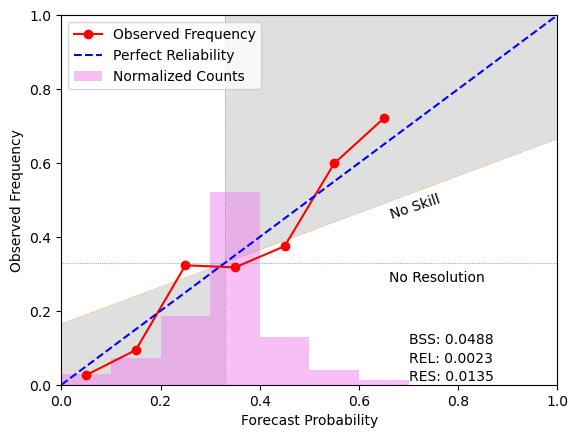

In [28]:
reliability_diagram(nonz_terciles_f, nonz_ohe_f)

In [29]:
## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [30]:
ohe_mat = np.zeros((32,31,140,3))

y_test = data_obs_test['prcp'].values

y_test.shape

for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

ohe_mat.shape

(32, 31, 140, 3)

In [31]:
week2_elr_terciles.shape

(32, 31, 140, 3)

In [32]:
flattened_terciles = week2_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

nonz_terciles_f = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

nonz_ohe_f = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

nonz_terciles_f.shape

nonz_ohe_f.shape

(416640,)

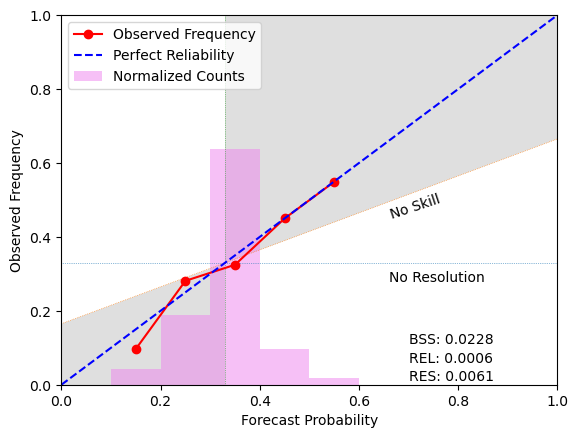

In [33]:
reliability_diagram(nonz_terciles_f, nonz_ohe_f)

In [34]:
## training data

week = '34'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [35]:
ohe_mat = np.zeros((32,31,140,3))

y_test = data_obs_test['prcp'].values

y_test.shape

for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

ohe_mat.shape

(32, 31, 140, 3)

In [36]:
week34_elr_terciles.shape

(32, 31, 140, 3)

In [37]:
flattened_terciles = week34_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

nonz_terciles_f = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

nonz_ohe_f = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

nonz_terciles_f.shape

nonz_ohe_f.shape

(416640,)

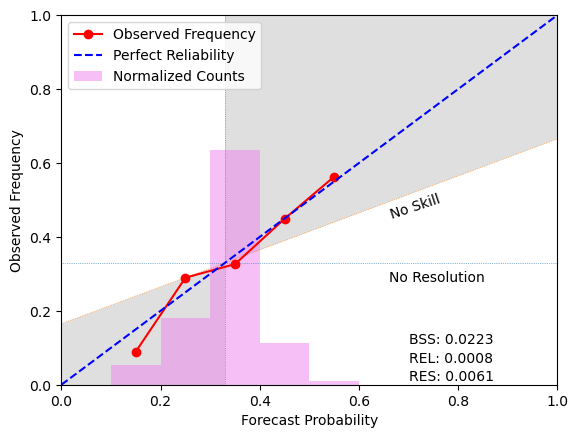

In [38]:
reliability_diagram(nonz_terciles_f, nonz_ohe_f)

In [254]:
def reliability_diagram(y_pred_qrf, t_qrf, y_pred_elr, t_elr, title=None, perfect_reliability_line=True, plot_hist=True, fig=None, ax=None, bin_minimum_pct=0.01, tercile_skill_area=True, scores=True, week=None):
    """
    Compute and plot a reliability diagram (calibration curve) with a normalized histogram of the forecast probabilities
    for both QRF and ELR models.

    Parameters:
    y_pred_qrf (numpy array): Predicted probabilities from QRF model.
    t_qrf (numpy array): True binary outcomes from QRF model.
    y_pred_elr (numpy array): Predicted probabilities from ELR model.
    t_elr (numpy array): True binary outcomes from ELR model.
    title (str): Title for the plot.
    perfect_reliability_line (bool): Whether to plot the perfect reliability line.
    plot_hist (bool): Whether to plot the histogram of forecast probabilities.
    fig (matplotlib Figure): Figure object to plot on.
    ax (matplotlib Axes): Axes object to plot on.
    bin_minimum_pct (float): Minimum percentage of samples in a bin to include it in the plot.
    """

    def compute_bin_stats(y_pred, t, num_bins=10):
        y_pred = y_pred * 0.9999999999999  # Avoids edge cases with digitize
        assert y_pred.shape == t.shape, 'Inconsistent shapes between ypred and t - {} vs {}'.format(y_pred.shape, t.shape)

        # Mask to remove NaNs
        msk = np.where(~np.isnan(y_pred + t))
        y_pred = y_pred[msk]
        t = t[msk]

        # Total number of non-NaN samples
        countnonnan = np.ones_like(y_pred).sum()

        # Initialize arrays
        bin_avg_pred = np.zeros(num_bins)
        bin_obs_freq = np.zeros(num_bins)
        bin_counts = np.zeros(num_bins)

        # Iterate over bins
        for i in range(num_bins):
            bin_mask = (y_pred >= i / 10.0) & (y_pred < (i / 10.0 + 0.1))
            bin_counts[i] = bin_mask.sum()

            if bin_counts[i] > 0:
                bin_avg_pred[i] = y_pred[bin_mask].mean()
                bin_obs_freq[i] = t[bin_mask].mean()

        # Compute bin centers
        bin_centers = (np.arange(num_bins) + 0.5) / num_bins

        # Mask bins with insufficient data
        valid_bins = bin_counts / countnonnan >= bin_minimum_pct
        bin_centers = bin_centers[valid_bins]
        bin_avg_pred = bin_avg_pred[valid_bins]
        bin_obs_freq = bin_obs_freq[valid_bins]
        bin_counts = bin_counts[valid_bins]

        # Normalize bin counts for the histogram
        bin_counts = bin_counts / countnonnan

        return bin_centers, bin_avg_pred, bin_obs_freq, bin_counts

    # Compute bin statistics for both QRF and ELR
    bin_centers_qrf, bin_avg_pred_qrf, bin_obs_freq_qrf, bin_counts_qrf = compute_bin_stats(y_pred_qrf, t_qrf)
    bin_centers_elr, bin_avg_pred_elr, bin_obs_freq_elr, bin_counts_elr = compute_bin_stats(y_pred_elr, t_elr)

    if ax is None:
        fig, ax = plt.subplots()

    # Plot the shaded "No Skill" and "No Resolution" areas
    if tercile_skill_area:
        ur = Polygon([[0.33, 0.33 ], [0.33, 1], [1,1], [1, 1.33/2.0]], facecolor='gray', alpha=0.25)
        bl = Polygon([[0.33, 0.33 ], [0.33, 0], [0,0], [0, 0.33/2.0]], facecolor='gray', alpha=0.25)
        ax.add_patch(ur)
        ax.add_patch(bl)

        ax.text(0.66, 0.28, 'No Resolution')
        noresolution = ax.plot([0, 1], [0.33,0.33], lw=0.5, linestyle='dotted')

        noskill = ax.plot([0, 1], [0.33/2.0,1.33/2.0], lw=0.5, linestyle='dotted')
        figW, figH = ax.get_figure().get_size_inches()
        _, _, w, h = ax.get_position().bounds
        disp_ratio = (figH * h) / (figW * w)
        data_ratio = sub(*ax.get_ylim()) / sub(*ax.get_xlim())
        angle = (180.0/np.pi)*np.arctan(disp_ratio / data_ratio)
        ax.text(0.66, 0.45, 'No Skill', rotation=angle*0.5)

        ax.plot([0.33, 0.33], [0,1], lw=0.5, linestyle='dotted')

    # Plot the reliability diagram for QRF
    ax.plot(bin_centers_qrf, bin_obs_freq_qrf, marker='o', linestyle='-', color='#008080', label='QRF')

    # Plot the reliability diagram for ELR
    ax.plot(bin_centers_elr, bin_obs_freq_elr, marker='o', linestyle='-', color='#FF1493', label='ELR')

    # Plot the perfect reliability line
    if perfect_reliability_line:
        ax.plot([0, 1], [0, 1], linestyle='--', color='blue', label='Perfect Reliability')

    # Plot normalized histogram as step plot
    if plot_hist:
        ax.bar(bin_centers_qrf, bin_counts_qrf, width=0.1, color='#008080', alpha=0.5, label='QRF Normalized')
        ax.bar(bin_centers_elr, bin_counts_elr, width=0.1, color='#FF1493', alpha=0.5, label='ELR Normalized')

    if scores:
        bss_qrf = compute_brier_skill_score(y_pred_qrf, t_qrf)
        rel_qrf = compute_reliability_score(t_qrf, y_pred_qrf)
        res_qrf = compute_resolution_score(y_pred_qrf, t_qrf)

        bss_elr = compute_brier_skill_score(y_pred_elr, t_elr)
        rel_elr = compute_reliability_score(t_elr, y_pred_elr)
        res_elr = compute_resolution_score(y_pred_elr, t_elr)

        ax.text(0.75, 0.48, f'QRF BSS: {bss_qrf:.4f}\nQRF REL: {rel_qrf:.4f}\nQRF RES: {res_qrf:.4f}', 
                verticalalignment='top', transform=ax.transAxes, color='#008080')
        ax.text(0.75, 0.25, f'ELR BSS: {bss_elr:.4f}\nELR REL: {rel_elr:.4f}\nELR RES: {res_elr:.4f}', 
                verticalalignment='top', transform=ax.transAxes, color='#FF1493')

    ax.set_xlabel('Forecast Probability')
    ax.set_ylabel('Observed Frequency')
    ax.set_ylim([0, 1])
    ax.set_xlim([0, 1])
    if title is not None:
        ax.set_title(title)
    ax.legend(loc='upper left')
    
    if len(str(week))>1:
        plt.title(f'Weeks {str(week)[0]}&{str(week)[1]} Reliability Diagram')
    else:
        plt.title(f'Week {str(week)} Reliability Diagram')
    
    plt.savefig(f'./plots/Reliability Diagram - Week {week}.jpg', dpi=600)
    
    return bin_centers_qrf, bin_avg_pred_qrf, bin_obs_freq_qrf, bin_counts_qrf

In [255]:
y_pred_qrf = np.load('nonz_terciles_f_1.npy')
t_qrf = np.load('nonz_ohe_f_1.npy')

In [256]:
## training data

week = '1'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

ohe_mat = np.zeros((32,31,140,3))

y_test = data_obs_test['prcp'].values

y_test.shape

for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

ohe_mat.shape

week1_elr_terciles.shape

flattened_terciles = week1_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

nonz_terciles_f_elr = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

nonz_ohe_f_elr = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

In [257]:
nonz_ohe_f_elr.shape

(416640,)

(array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85]),
 array([0.0569642 , 0.15253421, 0.25104759, 0.34638627, 0.44559555,
        0.54771774, 0.64652331, 0.74382506, 0.84160844]),
 array([0.08932806, 0.20118101, 0.28819274, 0.35129364, 0.40201433,
        0.4676158 , 0.56356471, 0.6597737 , 0.76919087]),
 array([0.10006328, 0.17414175, 0.22523335, 0.18894162, 0.11152508,
        0.07889574, 0.06222117, 0.04054738, 0.01525075]))

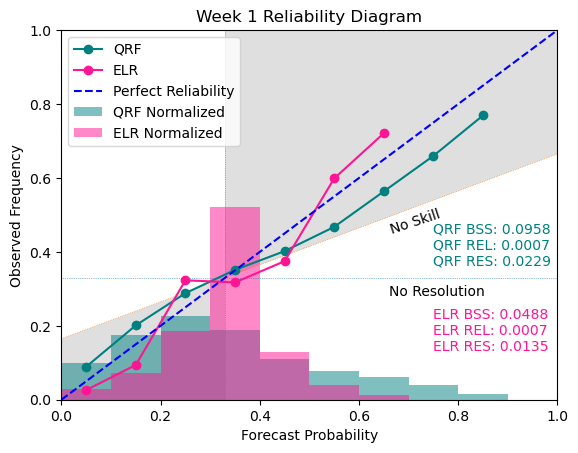

In [258]:
reliability_diagram(y_pred_qrf, t_qrf, nonz_terciles_f_elr, nonz_ohe_f_elr, week=1)


(array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75]),
 array([0.06513763, 0.15403607, 0.25214427, 0.3474314 , 0.44396216,
        0.54737231, 0.64615313, 0.74433617]),
 array([0.1471399 , 0.22557323, 0.29919562, 0.34273458, 0.38139288,
        0.44597015, 0.53006859, 0.60348653]),
 array([0.06886569, 0.15317197, 0.24584718, 0.23418763, 0.13425091,
        0.07949692, 0.04958867, 0.02495649]))

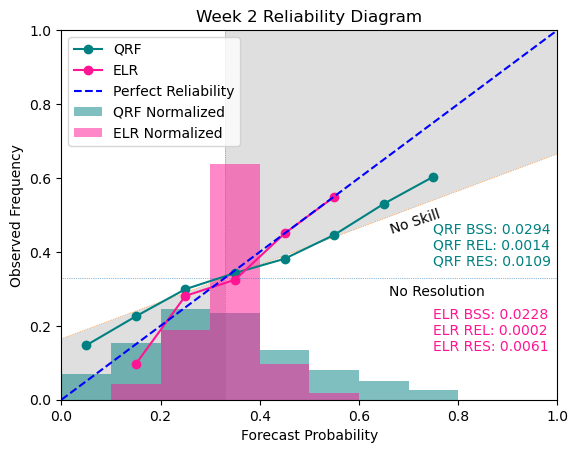

In [259]:
y_pred_qrf = np.load('nonz_terciles_f_2.npy')
t_qrf = np.load('nonz_ohe_f_2.npy')

## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

ohe_mat = np.zeros((32,31,140,3))

y_test = data_obs_test['prcp'].values

y_test.shape

for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

ohe_mat.shape

flattened_terciles = week2_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

nonz_terciles_f_elr = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

nonz_ohe_f_elr = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

nonz_ohe_f_elr.shape

reliability_diagram(y_pred_qrf, t_qrf, nonz_terciles_f_elr, nonz_ohe_f_elr, week=2)

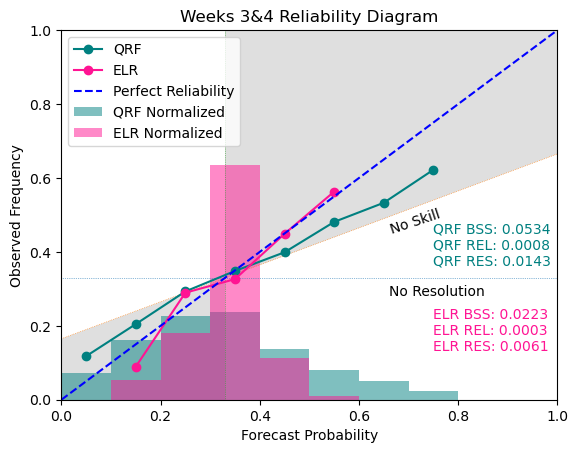

(array([0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75]),
 array([0.06570316, 0.15286085, 0.25195375, 0.34784598, 0.44499673,
        0.54678023, 0.64567414, 0.74452033]),
 array([0.1179402 , 0.20463641, 0.29301581, 0.34834825, 0.39903595,
        0.48114866, 0.53292936, 0.62215628]),
 array([0.07142857, 0.16207879, 0.22719506, 0.23777092, 0.13620471,
        0.08098402, 0.04960449, 0.02399146]))

In [45]:
y_pred_qrf = np.load('nonz_terciles_f_34.npy')
t_qrf = np.load('nonz_ohe_f_34.npy')

## training data

week = '34'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

ohe_mat = np.zeros((32,31,140,3))

y_test = data_obs_test['prcp'].values

y_test.shape

for i in range(32):
    for j in range(31):
        ohe_mat[i,j,:,:],_,_ = make_ohe(y_test[:,i,j])

ohe_mat.shape

flattened_terciles = week34_elr_terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

nonz_terciles_f_elr = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

nonz_ohe_f_elr = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

nonz_ohe_f_elr.shape

reliability_diagram(y_pred_qrf, t_qrf, nonz_terciles_f_elr, nonz_ohe_f_elr, week=34)